# 10. ESTBAN por banco: o degrau de agosto/2019 e a série de crédito dos modelos

Responde à pergunta 2 do roteiro (`docs/02_roteiro_eda.md`): o degrau de `credito_total` em agosto/2019 (de 30,3 para 6,5 bilhões, -79% em um único mês) é mudança real de crédito em Santos ou artefato de reporte no ESTBAN?

**Como separar as hipóteses.** Se a queda fosse mudança real, esperaríamos que ela se distribuísse entre vários bancos ou viesse com fechamento de agências. Se fosse artefato de reporte, esperaríamos que ela se concentrasse em uma instituição, sem mudança no número de agências.

**Dados.** `estban_verbetes_santos_2015-2025_por_banco.csv` (ESTBAN, Santos, 2015-2025, por banco e verbete, obtido na Base dos Dados) e `estban_agencias_santos_2015-2025_por_banco.csv`. A consulta de 2019 feita antes (`verbete-por-banco-2019`) é um subconjunto deste arquivo e foi conferida: as duas são idênticas nos meses em comum.

**O que o notebook decide:** a série de crédito que entra nos modelos (notebooks 11 e 12) e a amostra de modelagem. A causa do degrau **não é documentada publicamente**; o que segue é diagnóstico dos dados, não prova da causa.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# lê os arquivos da pasta local do repositório quando ela existe; senão, direto do GitHub
RAIZ = 'https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/'

def ler(caminho, **kw):
    local = os.path.join('..', caminho)
    return pd.read_csv(local if os.path.exists(local) else RAIZ + caminho, **kw)

def fmt(x, casas=2):
    """número com vírgula decimal"""
    return f'{x:.{casas}f}'.replace('.', ',')

def fmtp(p):
    """p-valor no estilo do artigo"""
    return '<0,0001' if p < 0.0001 else fmt(p, 4)

from statsmodels.tsa.stattools import adfuller, zivot_andrews
import statsmodels.api as sm

por_banco = ler('data/raw/estban_verbetes_santos_2015-2025_por_banco.csv', dtype={'cnpj_basico': str})
por_banco['data'] = pd.to_datetime(dict(year=por_banco['ano'], month=por_banco['mes'], day=1))
agencias = ler('data/raw/estban_agencias_santos_2015-2025_por_banco.csv', dtype={'cnpj_basico': str})
agencias['data'] = pd.to_datetime(dict(year=agencias['ano'], month=agencias['mes'], day=1))
painel = ler('data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(dict(year=painel['ano'], month=painel['mes'], day=1))
painel = painel.set_index('data')

BRADESCO = '60746948'
credito = por_banco[por_banco['id_verbete'] == 160]
ativo = por_banco[por_banco['id_verbete'] == 399]

total = credito.groupby('data')['valor_total'].sum()
bradesco = credito[credito['cnpj_basico'] == BRADESCO].set_index('data')['valor_total']
ex_bradesco = total - bradesco

print(f"{len(por_banco)} linhas, {por_banco['instituicao'].nunique()} instituições, "
      f"{por_banco['data'].min():%Y-%m} a {por_banco['data'].max():%Y-%m}")

6564 linhas, 12 instituições, 2015-01 a 2025-12


## 1. Validação: a soma por banco reproduz o painel

Antes de abrir por banco, confirma-se que somar os bancos devolve exatamente o `credito_total` do painel nos meses que o painel cobre (até set/2025). Se não batesse, o arquivo por banco não seria a mesma série.

In [2]:
comum = painel['credito_total'].dropna().index
dif_max = (total.reindex(comum) - painel.loc[comum, 'credito_total']).abs().max()
print(f'maior diferença absoluta entre a soma por banco e o painel: R$ {dif_max:,.0f}'.replace(',', '.'))
print(f'meses comparados: {len(comum)}')

maior diferença absoluta entre a soma por banco e o painel: R$ 0
meses comparados: 129


## 2. O degrau por banco

Crédito (verbete 160) por banco em julho e agosto de 2019, em R$ bilhões, com o número de agências processadas no município nos mesmos meses.

In [3]:
jul, ago = pd.Timestamp('2019-07-01'), pd.Timestamp('2019-08-01')
tab = credito[credito['data'].isin([jul, ago])].pivot_table(index='instituicao', columns='data', values='valor_total') / 1e9
tab.columns = ['jul/2019', 'ago/2019']
ag = agencias[agencias['data'].isin([jul, ago])].pivot_table(index='instituicao', columns='data', values='agencias_processadas')
ag.columns = ['agências jul', 'agências ago']
tab = tab.join(ag)
tab['variação'] = (tab['ago/2019'] / tab['jul/2019'] - 1) * 100
tab = tab.dropna(subset=['jul/2019']).sort_values('jul/2019', ascending=False)
display(tab.round(2))

queda_total = (total[ago] / total[jul] - 1) * 100
var_demais = (ex_bradesco[ago] / ex_bradesco[jul] - 1) * 100
display(Markdown(
    f"**Total:** R$ {total[jul]/1e9:.1f} bi → R$ {total[ago]/1e9:.1f} bi ({queda_total:.1f}%). "
    f"**Bradesco:** R$ {bradesco[jul]/1e9:.1f} bi → R$ {bradesco[ago]/1e9:.2f} bi ({(bradesco[ago]/bradesco[jul]-1)*100:.1f}%). "
    f"**Demais bancos:** R$ {ex_bradesco[jul]/1e9:.2f} bi → R$ {ex_bradesco[ago]/1e9:.2f} bi ({var_demais:+.1f}%).".replace('.', ',')
))

,jul/2019,ago/2019,agências jul,agências ago,variação
instituicao,,,,,
BCO BRADESCO S.A.,23.87,0.08,26.0,26.0,-99.65
CAIXA ECONOMICA FEDERAL,3.75,3.76,14.0,14.0,0.26
BCO DO BRASIL S.A.,1.43,1.44,16.0,15.0,0.14
BCO SANTANDER (BRASIL) S.A.,0.58,0.59,18.0,18.0,2.20
ITAÚ UNIBANCO S.A.,0.50,0.50,16.0,16.0,1.12
BCO SAFRA S.A.,0.12,0.13,1.0,1.0,7.01
BCO MERCANTIL DO BRASIL S.A.,0.00,0.00,1.0,1.0,3.67
BCO CITIBANK S.A.,0.00,0.00,1.0,1.0,0.00


**Total:** R$ 30,3 bi → R$ 6,5 bi (-78,5%), **Bradesco:** R$ 23,9 bi → R$ 0,08 bi (-99,6%), **Demais bancos:** R$ 6,38 bi → R$ 6,42 bi (+0,6%),

Em agosto de 2019 a queda está em uma única instituição. Os demais bancos variam menos de 1% e o Bradesco mantém as 26 agências em Santos. **Isso não é fechamento de agências nem retração geral do crédito local.**

## 3. O ativo do Bradesco no mesmo mês

O verbete 399 (ativo total) do Bradesco acompanha o degrau. Um banco com 26 agências em Santos passar de cerca de R$ 3 bilhões para R$ 70 bilhões de ativo e voltar é incompatível com a operação local, o que sugere um saldo de natureza não local lançado no município e depois retirado. É **hipótese bem sustentada pelos dados, não fato comprovado**.

In [4]:
ativo_brad = ativo[ativo['cnpj_basico'] == BRADESCO].set_index('data')['valor_total']
print(ativo_brad['2019-01':'2019-12'].div(1e9).round(1).to_string())

data
2019-01-01    21.0
2019-02-01    64.9
2019-03-01    68.0
2019-04-01    66.3
2019-05-01    66.2
2019-06-01    68.3
2019-07-01    69.9
2019-08-01     3.1
2019-09-01     3.1
2019-10-01     3.1
2019-11-01     3.2
2019-12-01     3.3


## 4. A volatilidade anterior a 2019 vem do mesmo banco

Coeficiente de variação (desvio padrão sobre a média) e maior variação mensal em módulo, de 2015 a 2024, com e sem o Bradesco. Recorte até 2024 porque 2025 tem buracos de reporte (seção 7).

In [5]:
t = total['2015':'2024']
e = ex_bradesco['2015':'2024']
cv_t, cv_e = t.std() / t.mean(), e.std() / e.mean()
mx_t, mx_e = t.pct_change().abs().max() * 100, e.pct_change().abs().max() * 100
display(pd.DataFrame({'credito_total': [cv_t, mx_t], 'sem o Bradesco': [cv_e, mx_e]},
                     index=['coeficiente de variação', 'maior variação mensal (%)']).round(2))

maiores = t.pct_change().mul(100).abs().sort_values(ascending=False).head(4)
print('\nquatro maiores movimentos mensais do crédito total (%, com sinal):')
print(t.pct_change().mul(100).loc[maiores.index].sort_index().round(0).to_string())

,credito_total,sem o Bradesco
coeficiente de variação,0.50,0.17
maior variação mensal (%),86.64,6.48



quatro maiores movimentos mensais do crédito total (%, com sinal):
data
2016-06-01    77.0
2016-10-01    87.0
2019-01-01    63.0
2019-08-01   -79.0


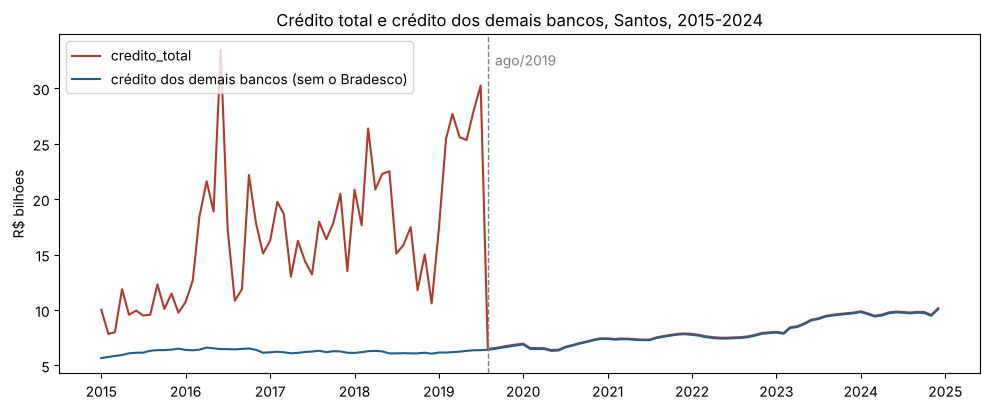

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t.index, t / 1e9, label='credito_total', color='#b03a2e')
ax.plot(e.index, e / 1e9, label='crédito dos demais bancos (sem o Bradesco)', color='#1f618d')
ax.axvline(pd.Timestamp('2019-08-01'), color='gray', ls='--', lw=1)
ax.text(pd.Timestamp('2019-09-01'), ax.get_ylim()[1] * 0.92, 'ago/2019', color='gray')
ax.set_ylabel('R$ bilhões')
ax.set_title('Crédito total e crédito dos demais bancos, Santos, 2015-2024')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 5. Participação do Bradesco no crédito

Três formas de medir, porque a escolha muda o número: acumulada no período (soma do Bradesco sobre soma do total), média das participações mensais, e média mensal antes e depois do degrau. A participação mudou de cerca de três quartos do crédito para quase nada, então **uma única média esconde o que aconteceu**.

In [7]:
part = (bradesco / total)
acum = bradesco['2015':'2025'].sum() / total['2015':'2025'].sum()
print(f"participação acumulada 2015-2025 (soma/soma): {acum*100:.1f}%  -> perda de cobertura ao excluir o Bradesco")
print(f"média das participações mensais 2015-2025:     {part['2015':'2025'].mean()*100:.1f}%")
print(f"média mensal 2015-01 a 2019-07:                {part[:'2019-07'].mean()*100:.1f}%")
print(f"média mensal jan a jul/2019:                   {part['2019-01':'2019-07'].mean()*100:.1f}%")
print(f"média mensal 2019-08 em diante:                {part['2019-08':].mean()*100:.1f}%")
print(f"média mensal nos 12 meses seguintes (ago/2019 a jul/2020): {part['2019-08':'2020-07'].mean()*100:.1f}%")

participação acumulada 2015-2025 (soma/soma): 38.0%  -> perda de cobertura ao excluir o Bradesco
média das participações mensais 2015-2025:     24.7%
média mensal 2015-01 a 2019-07:                58.0%
média mensal jan a jul/2019:                   74.9%
média mensal 2019-08 em diante:                0.9%
média mensal nos 12 meses seguintes (ago/2019 a jul/2020): 1.2%


## 6. Teste de quebra estrutural de Zivot e Andrews

O ADF em `credito_total` classifica a série como estacionária apenas por causa do degrau (Perron, 1989). O teste de Zivot e Andrews (1992) escolhe a data de quebra de forma endógena e testa raiz unitária admitindo uma quebra na média. Aplicado às duas séries (2015-2024, em nível, constante, defasagens pelo AIC):

In [8]:
linhas = []
for nome, s in [('credito_total', t), ('crédito sem o Bradesco', e)]:
    est, pv, crit, base, idx = zivot_andrews(s.values, regression='c', autolag='AIC')
    linhas.append({'série': nome, 'estatística': est, 'p-valor': pv, 'quebra em': s.index[idx].strftime('%Y-%m')})
display(pd.DataFrame(linhas).round(4))

,série,estatística,p-valor,quebra em
0,credito_total,-8.3845,0.0000,2019-07
1,crédito sem o Bradesco,-3.7137,0.5378,2023-02


O teste localiza a quebra do `credito_total` em julho de 2019 (último mês antes do degrau) com p < 0,0001. No crédito sem o Bradesco **não há quebra detectada** (p = 0,54): a data que aparece na tabela é só o melhor candidato do teste, e o p-valor mostra que ele não é significativo.

## 7. As quatro alternativas para o crédito (Quadro 3 do artigo)

**A. `credito_total` em nível.** O ADF o classifica como I(0), mas só por causa do degrau.

In [9]:
painel_credito = painel['credito_total'].dropna()      # jan/2015 a set/2025, 129 meses
r = adfuller(painel_credito, regression='c', autolag='AIC')
print(f'A. ADF em nível, painel_credito ({len(painel_credito)} meses): estatística {r[0]:.2f}, p = {r[1]:.4f}  -> classificado como estacionário')

A. ADF em nível, painel_credito (129 meses): estatística -3.08, p = 0.0282  -> classificado como estacionário


**B. `credito_total` em primeira diferença.** O degrau vira um único ponto extremo, medido em desvios padrão da série diferenciada, e a variância é diferente nos dois regimes.

In [10]:
d = painel_credito.diff().dropna()
z = (d.loc['2019-08-01'] - d.mean()) / d.std()
print(f'B. variação de ago/2019 = {z:.1f} desvios padrão da série diferenciada')

B. variação de ago/2019 = -6.1 desvios padrão da série diferenciada


**C. `credito_total` em nível com variável indicadora do degrau.** Regressão do log do crédito em constante, tendência linear e indicadora (1 a partir de ago/2019). A indicadora corrige a média, mas os resíduos continuam com variância muito diferente nos dois regimes.

In [11]:
y = np.log(t)
n = len(y)
deg = (y.index >= '2019-08-01').astype(float)
X = np.column_stack([np.ones(n), np.arange(n), deg])
res = sm.OLS(y.values, X).fit().resid
print(f'C. desvio padrão dos resíduos: {res[deg == 0].std(ddof=1):.2f} antes do degrau, {res[deg == 1].std(ddof=1):.2f} depois')

C. desvio padrão dos resíduos: 0.28 antes do degrau, 0.07 depois


**D. Crédito dos demais bancos.** Sem quebra detectada (Zivot e Andrews, seção 6), I(1) (notebook 11) e variabilidade estável (seção 4). O preço é a cobertura: o crédito sem o Bradesco representa cerca de 62% do crédito acumulado das agências de Santos no período (seção 5). Continua sendo **crédito das agências bancárias de Santos**, agora sem a instituição cujo saldo parece não corresponder à operação local. **Não é crédito ao Porto de Santos nem ao comércio exterior.**

**Decisão:** D é a série principal da modelagem, de jan/2015 a dez/2024.

## 8. Buracos de reporte em 2025 e a amostra de modelagem

A consulta por banco traz também out-dez/2025, mas 2025 tem meses em que bancos específicos não aparecem com valor. Somar os bancos que sobram trata o saldo faltante como zero e cria quedas artificiais no agregado.

In [12]:
buracos = por_banco[por_banco['valor_total'].isna()].groupby(['ano', 'mes', 'instituicao']).size().rename('verbetes sem valor').reset_index()
display(buracos)
print(f'pares banco-mês com valor ausente: {len(buracos)} (todos em {sorted(buracos["ano"].unique())})')
print(f'anos anteriores a 2025 com valor ausente: {por_banco[por_banco["data"] < "2025-01-01"]["valor_total"].isna().sum()}')

,ano,mes,instituicao,verbetes sem valor
0,2025,2,ITAÚ UNIBANCO S.A.,6
1,2025,3,BCO SANTANDER (BRASIL) S.A.,6
2,2025,3,ITAÚ UNIBANCO S.A.,6
3,2025,4,BCO SANTANDER (BRASIL) S.A.,6
4,2025,4,ITAÚ UNIBANCO S.A.,6
5,2025,5,ITAÚ UNIBANCO S.A.,6
6,2025,7,BCO DO BRASIL S.A.,6


pares banco-mês com valor ausente: 7 (todos em [np.int64(2025)])
anos anteriores a 2025 com valor ausente: 0


Nenhum valor ausente de 2015 a 2024. A amostra de modelagem com crédito fica em **jan/2015 a dez/2024 (120 meses)**, e `src/build_modeling_panel.py` gera `data/processed/painel_modelagem_2015_2025.csv` já com essa regra (a coluna `credito_ex_bradesco` fica vazia em 2025).

## Conclusões

1. A queda de agosto de 2019 está concentrada em uma instituição, sem mudança no número de agências: indica artefato de reporte, não retração do crédito local.
2. A volatilidade do crédito agregado antes de 2019 vem do mesmo banco (coeficiente de variação de 0,50 para 0,17 sem ele).
3. A série de crédito dos modelos é o crédito dos demais bancos, de jan/2015 a dez/2024.
4. **Em aberto:** a causa do saldo do Bradesco depende de confirmação do Banco Central; o pedido está registrado (artigo, seção 7).